In [ ]:
import datetime

import matplotlib.pyplot as plt
import numpy as np
from rocketpy import Environment, Flight, Rocket, SolidMotor, utilities

%config InlineBackend.figure_formats = ['svg']
%matplotlib inline

import Escalante
import MonteCarlo
import SpaceportEnvironment as SE


In [ ]:
windyEnv = SE.returnWindyEnvironment()
constantEnv = SE.returnConstantEnvironment()
AeroTech_O5500X = Escalante.DefineMotor()
escalante = Escalante.DefineEscalante()

# SE.printWindyEnvironment()
# SE.printConstantEnvironment()
# Escalante.PrintMotorDetails()
# Escalante.PrintEscalante()


Gravity Details

Acceleration of gravity at surface level:    9.7913 m/s²
Acceleration of gravity at  12.000 km (ASL): 9.7587 m/s²


Launch Site Details

Launch Date: 2024-10-30 12:00:00 UTC
Launch Site Latitude: 32.94104°
Launch Site Longitude: -106.92204°
Reference Datum: SIRGAS2000
Launch Site UTM coordinates: 320318.11 W    3646389.34 N
Launch Site UTM zone: 13S
Launch Site Surface Elevation: 1384.0 m


Atmospheric Model Details

Atmospheric Model Type: Windy
Windy Maximum Height: 12.000 km

Surface Atmospheric Conditions

Surface Wind Speed: 2.54 m/s
Surface Wind Direction: 300.36°
Surface Wind Heading: 120.36°
Surface Pressure: 859.86 hPa
Surface Temperature: 283.34 K
Surface Air Density: 1.057 kg/m³
Surface Speed of Sound: 337.44 m/s


Earth Model Details

Earth Radius at Launch site: 6371.85 km
Semi-major Axis: 6378.14 km
Semi-minor Axis: 6356.75 km
Flattening: 0.0034



Gravity Model Plots


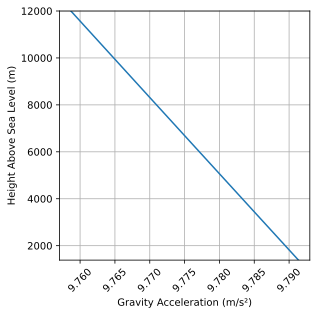



Atmospheric Model Plots


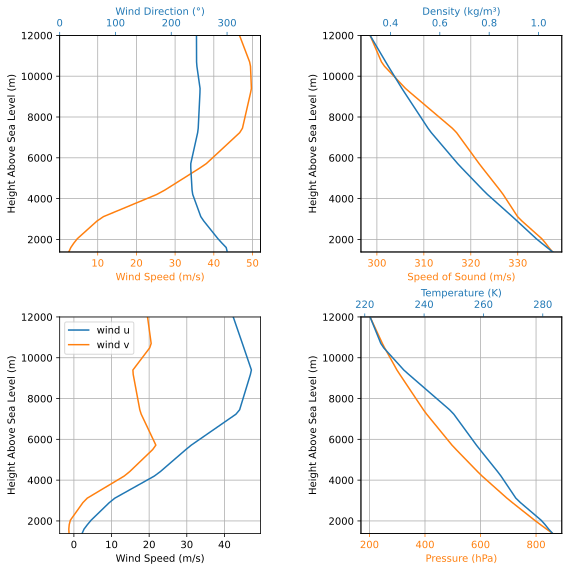

In [ ]:
windyEnv.all_info()

In [ ]:
escalante = Escalante.addParachutes()

29936.190969240477

Initial Conditions

Initial time: 0.000 s
Position - x: 0.00 m | y: 0.00 m | z: 1386.00 m
Velocity - Vx: 0.00 m/s | Vy: 0.00 m/s | Vz: 0.00 m/s
Attitude (quaternions) - e0: 0.998 | e1: -0.036 | e2: 0.038 | e3: -0.032
Euler Angles - Spin φ : 45.00° | Nutation θ: -6.00° | Precession ψ: -48.62°
Angular Velocity - ω1: 0.00 rad/s | ω2: 0.00 rad/s | ω3: 0.00 rad/s
Initial Stability Margin: 1.513 c


Surface Wind Conditions

Frontal Surface Wind Speed: 4.01 m/s
Lateral Surface Wind Speed: -0.00 m/s


Launch Rail

Launch Rail Length: 5.2 m
Launch Rail Inclination: 84.00°
Launch Rail Heading: 48.62°


Rail Departure State

Rail Departure Time: 0.251 s
Rail Departure Velocity: 41.040 m/s
Rail Departure Stability Margin: 1.597 c
Rail Departure Angle of Attack: 5.609°
Rail Departure Thrust-Weight Ratio: 19.750
Rail Departure Reynolds Number: 3.744e+05


Burn out State

Burn out time: 3.997 s
Altitude at burn out: 2903.089 m (ASL) | 1517.089 m (AGL)
Rocket speed at burn out: 598

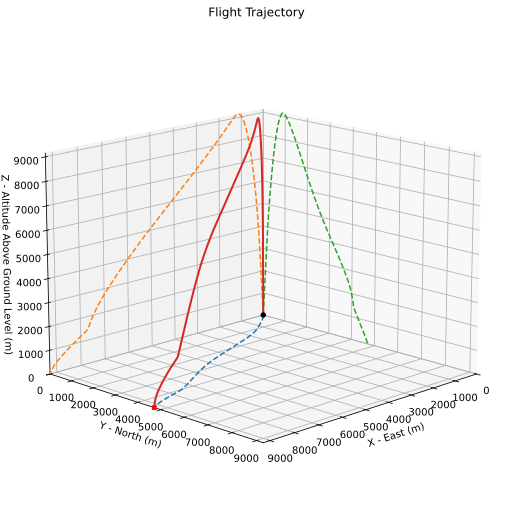



Trajectory Kinematic Plots



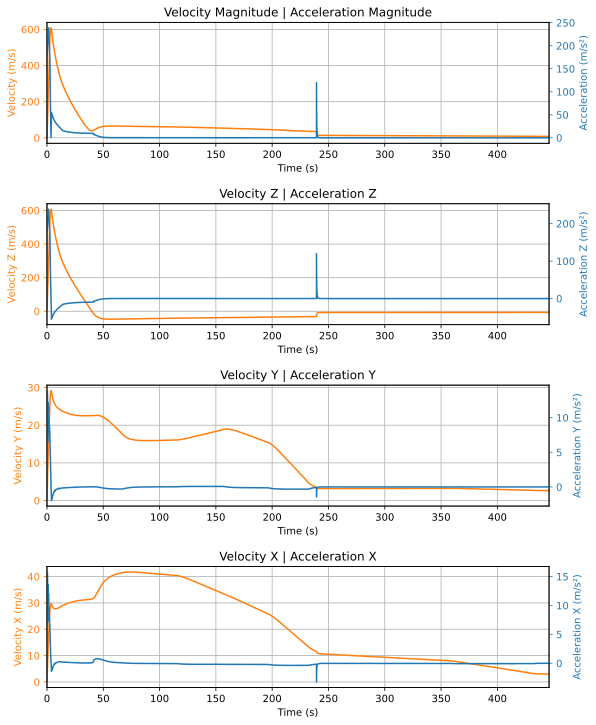



Angular Position Plots



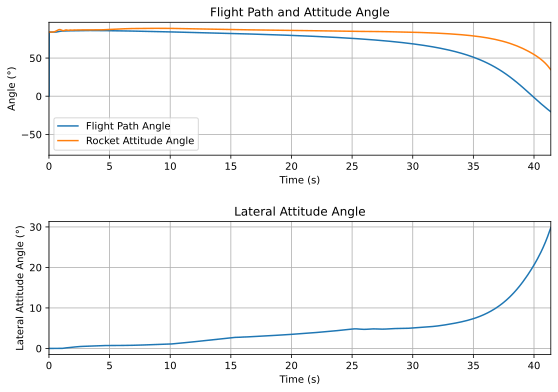



Path, Attitude and Lateral Attitude Angle plots



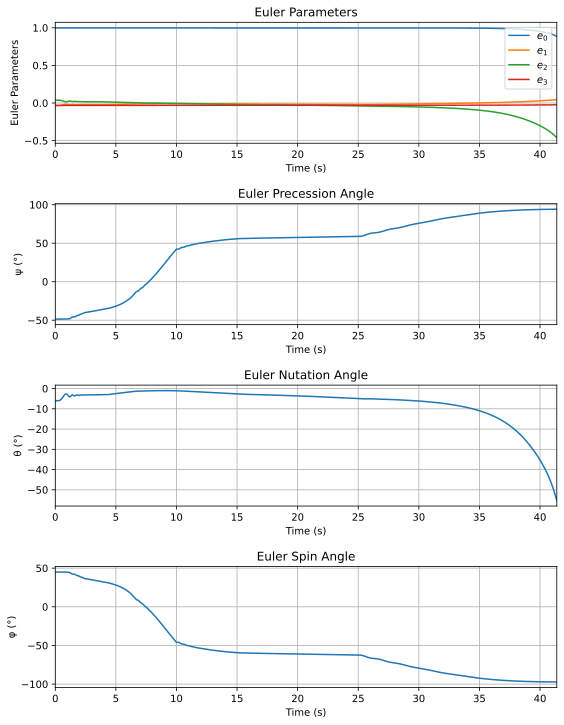



Trajectory Angular Velocity and Acceleration Plots



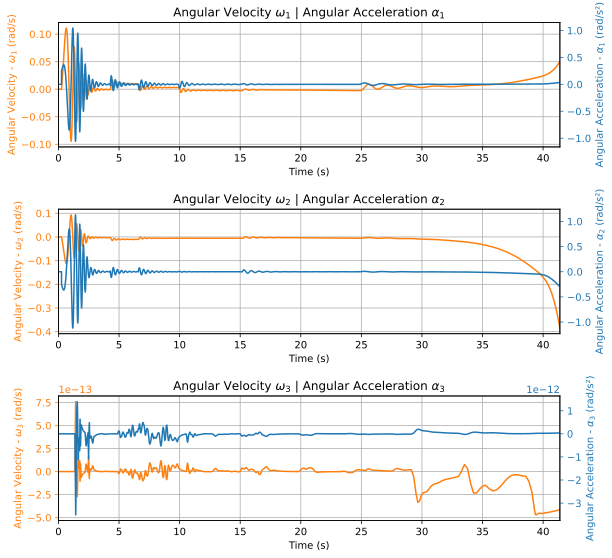



Aerodynamic Forces Plots



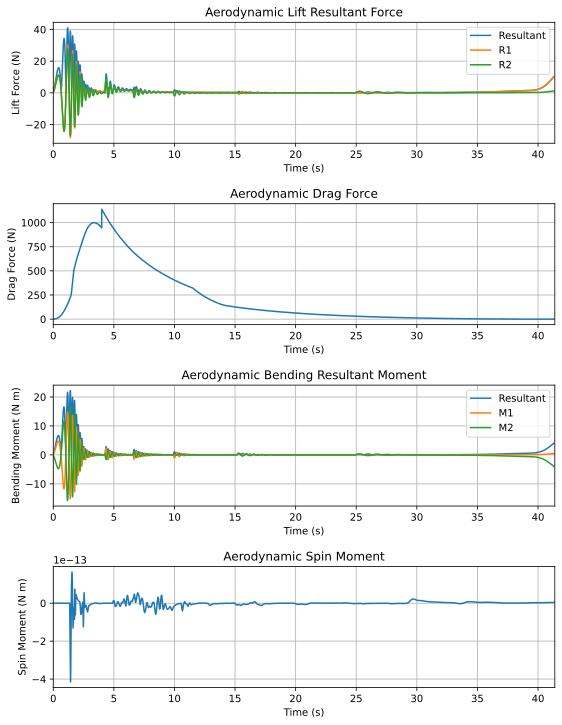



Rail Buttons Forces Plots



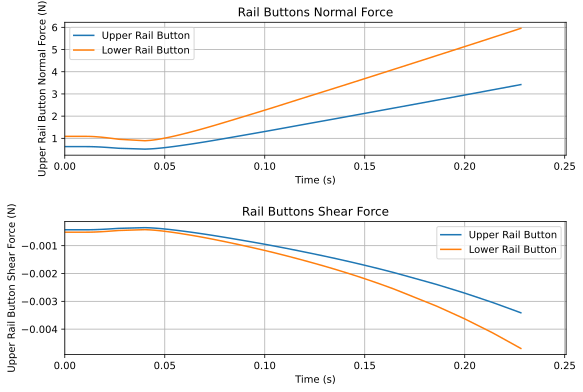



Trajectory Energy Plots



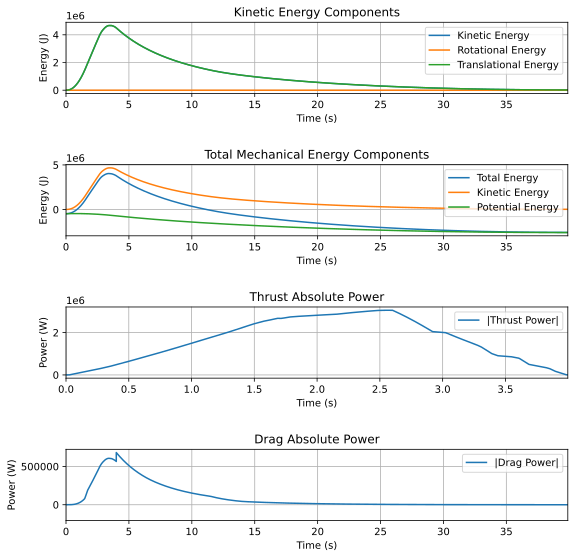



Trajectory Fluid Mechanics Plots



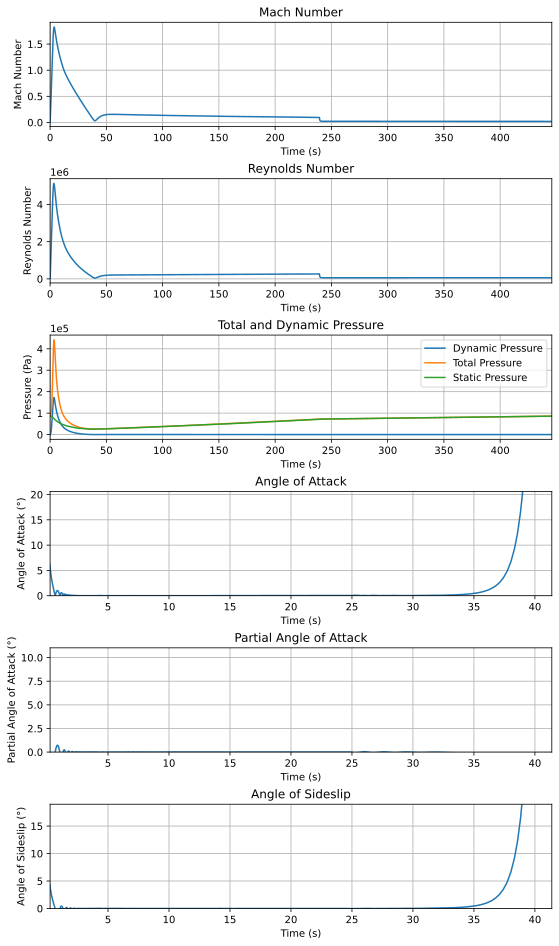



Trajectory Stability and Control Plots



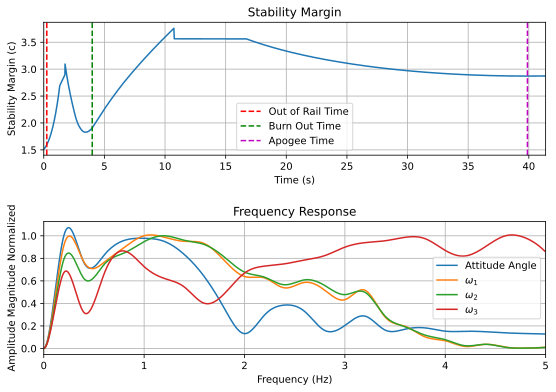



Rocket and Parachute Pressure Plots



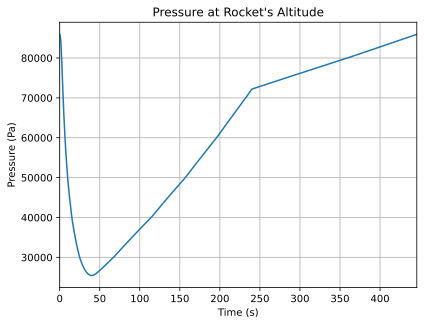


Parachute:  Main


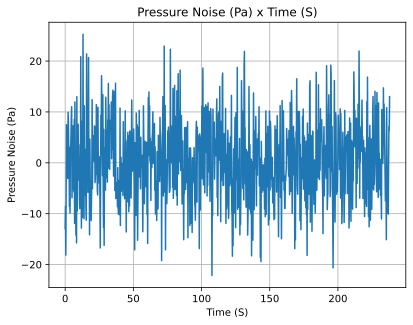

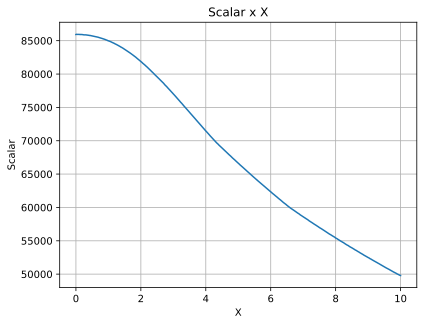

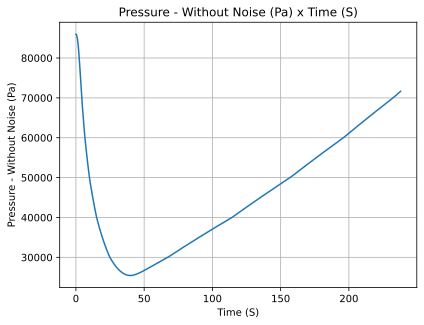


Parachute:  Drogue


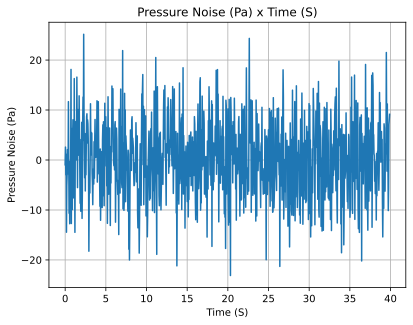

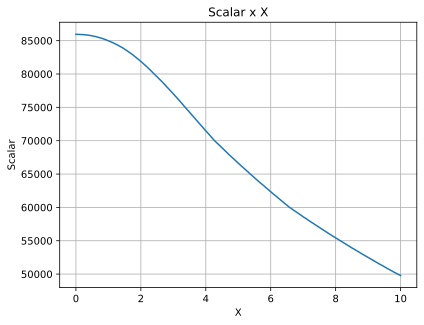

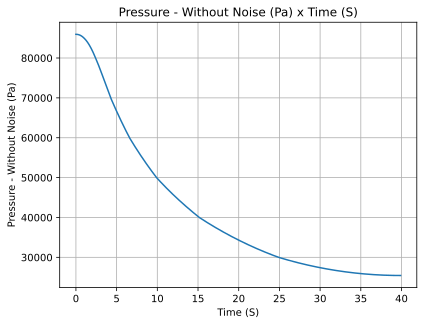

In [ ]:
test_flight = Flight(
    rocket=escalante, environment=windyEnv, rail_length=5.2, inclination=84, heading=48.62, max_time=1200
)
print((test_flight.apogee - 1408)*3.28084)
test_flight.all_info()

In [ ]:
from rocketpy.plots.compare import CompareFlights
from datetime import datetime, timedelta

inclinations = [84, 86]
headings = np.linspace(0, 359, 360)
flights = []

for heading in headings:
    for inclination in inclinations:
        flight = Flight(
            environment=windyEnv,
            rocket=escalante,
            rail_length=5.2,
            inclination=inclination,
            heading=heading,
            name=f"Incl {inclination} Head {heading}",
        )
        flights.append(flight)

comparison = CompareFlights(flights)

In [ ]:
test_flight.export_data("test_flight.csv")

In [ ]:
# Export to KML
test_flight.export_kml(
    file_name="trajectory.kml",
    extrude=True,
    altitude_mode="relative_to_ground",
)

File  trajectory.kml  saved with success!


In [ ]:
# Fin Flutter Analysis
utilities.fin_flutter_analysis(.00254, 1.420e+11, flight=test_flight, see_prints=False, see_graphs=False)

# Impacts on Apogee by increasing mass of rocket
utilities.apogee_by_mass(flight=test_flight, min_mass=16, max_mass=20, points=100, plot=False)

NameError: name 'test_flight' is not defined

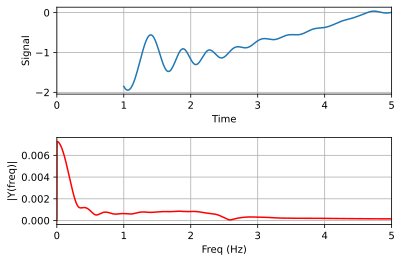

In [ ]:
# Simulate first 5 seconds of Flight
flight = Flight(
    rocket=escalante,
    environment=windyEnv,
    rail_length=5.2,
    inclination=86,
    heading=0,
    max_time_step=0.01,
    max_time=5,
)

# Perform a Fourier Analysis
Fs = 100.0
# sampling rate
Ts = 1.0 / Fs
# sampling interval
t = np.arange(1, 400, Ts)  # time vector
ff = 5
# frequency of the signal
y = flight.attitude_angle(t) - np.mean(flight.attitude_angle(t))
n = len(y)  # length of the signal
k = np.arange(n)
T = n / Fs
frq = k / T  # two sides frequency range
frq = frq[range(n // 2)]  # one side frequency range
Y = np.fft.fft(y) / n  # fft computing and normalization
Y = Y[range(n // 2)]

# Create the plot
fig, ax = plt.subplots(2, 1)
ax[0].plot(t, y)
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Signal")
ax[0].set_xlim((0, 5))
ax[0].grid()
ax[1].plot(frq, abs(Y), "r")  # plotting the spectrum
ax[1].set_xlabel("Freq (Hz)")
ax[1].set_ylabel("|Y(freq)|")
ax[1].set_xlim((0, 5))
ax[1].grid()
plt.subplots_adjust(hspace=0.5)
plt.show()

In [ ]:
Env = Environment(date=(2024, 10, 4, 18), latitude=32.94103529050622, longitude=-106.92203686488024, elevation=1385)
Env.max_expected_height = 12000
Env.set_atmospheric_model(
    type="Ensemble",
    file="GEFS"
)

Env.all_info()

oc_open: server error retrieving url: code=0 message="/gens_bc/gens20241001/gep_all_18z is not an available dataset"